# 05 · Agent conversations and reasoning analysis

This notebook looks *inside* the simulation: agents talk to each other, one pair at a time, and every opinion change is logged with the reasoning behind it. This is the "internal chat" of a MiroFish-style simulation, and the reasoning part of the evaluation.

### How a conversation works
Each round, agents are paired at random. In an exchange:
* the **speaker** states its main concern (its top aspect) and **cites a real review** about it, retrieved with BM25;
* the **listener** reacts and updates its buy intention:

  `new = old + w · (speaker − old) + evidence_weight · w · evidence_signal`

  with `w = min(0.9, susceptibility × speaker credibility × relevance of the topic to the listener)` and `evidence_signal = (stars − 3) / 2`.

### Methods used here, and why
| Method | Why |
|---|---|
| Random pairing | Simplest network, with no hidden structure driving the result (homophily or influencer-centred networks are roadmap items) |
| Speaker cites a *real* retrieved review | Every statement is grounded in the data; a conversation cannot invent a product fact |
| Explicit update rule with named terms | Each change is explainable and auditable |
| Opinions in logit space | Keeps intentions between 0 and 1 and makes steps comparable at high and low probabilities |
| Integrity checks | They verify **traceability** (every message cites a real review; every update can be recomputed from its logged terms). They do **not** validate the model against real consumers |
| Template sentences by default | Deterministic and free. An LLM can optionally phrase the replies, receiving only the logged facts |

**Assumed parameters:** the credibility mapping (normal 0.40, reviewer 0.55, influencer 1.00), the evidence weight (0.5) and the cap on `w` (0.9) are modelling assumptions, not fitted values.


In [1]:
# --- Setup (works in local Jupyter and on Colab) ---------------------------------------------
# Colab: run these once in a cell above, then restart if asked:
#   !git clone https://github.com/YOUR_USERNAME/mirofish-consumer-simulation.git
#   %cd mirofish-consumer-simulation
#   !pip install -r requirements.txt
import os, sys, subprocess, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repository root
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

def run(script, *args):
    """Run one project script exactly as you would from a terminal, and show the end of its output.
    Notebooks call the scripts (instead of copying their code) so there is a single source of truth in src/."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / script), "--project-dir", str(ROOT), *map(str, args)], capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])


In [2]:
run("conversations.py", "--append-report")      # also writes the section into outputs/report.md

      280                      0.054         49.643
technology_enthusiast       225                      0.044         48.889
competitor_customer         125                      0.043         48.800
professional_user           115                      0.030         43.478
camera_focused              130                      0.028         50.000

  round  mean_intention  std_intention
     0          0.9363         0.0239
     1          0.9413         0.0193
     2          0.9458         0.0162
     3          0.9494         0.0139
     4          0.9528         0.0124
     5          0.9558         0.0113

--- sample exchanges ---
**Round 1** | **Influencer** (agent 392) to **Technology Enthusiast** (agent 397) | topic: *reading*

> **Says:** As an influencer, my main concern is reading. A reviewer wrote "Great for reading. I like my new tablet which I use only for my reading" (4 stars), which fits my 94% buy intention.
>
> **Replies:** Reading matters about as much to me (relevance

In [3]:
L = pd.read_csv("outputs/conversation_log.csv")
print(f"{len(L):,} logged exchanges, rounds 1-{L['round'].max()}")
L["shift_toward"] = (L.logit_after - L.logit_before) * (L.speaker_logit - L.logit_before).apply(lambda x: 1 if x > 0 else -1)
display(pd.DataFrame({"reaction %": (L.reaction.value_counts(normalize=True)*100).round(1)}))

2,000 logged exchanges, rounds 1-5


,reaction %
reaction,
persuaded,50.4
agree,29.4
unmoved,20.2


## Read some conversations
Each exchange shows what the speaker said, how the listener replied, and the numbers behind the reply.

In [4]:
from conversations import dialogue_markdown
display(Markdown(dialogue_markdown(L, rnd=1, persona=None, limit=4)))

**Round 1** | **Influencer** (agent 392) to **Technology Enthusiast** (agent 397) | topic: *reading*

> **Says:** As an influencer, my main concern is reading. A reviewer wrote "Great for reading. I like my new tablet which I use only for my reading" (4 stars), which fits my 94% buy intention.
>
> **Replies:** Reading matters about as much to me (relevance 0.91) and an influencer seems very credible (credibility 1.00), so I move from 91.2% to 92.4%.
>
> *Reasoning terms: relevance 0.91, credibility 1.00, susceptibility 0.31, weight 0.29; reaction: persuaded; buy intention 91.2% to 92.4%*

**Round 1** | **Technology Enthusiast** (agent 397) to **Influencer** (agent 392) | topic: *price*

> **Says:** As a technology enthusiast, my main concern is price. A reviewer wrote "Good product for the price. Good product for the price - my granddaughter loved it" (4 stars), which fits my 92% buy intention.
>
> **Replies:** I hear it, but I'm not persuaded: I'm not very open to it (susceptibility 0.33, relevance 2.00), so I stay near 93.7%.
>
> *Reasoning terms: relevance 2.00, credibility 0.40, susceptibility 0.33, weight 0.26; reaction: unmoved; buy intention 93.6% to 93.7%*

**Round 1** | **Price Sensitive** (agent 118) to **Budget Conscious** (agent 225) | topic: *price*

> **Says:** As a price-sensitive buyer, my main concern is price. A reviewer wrote "Excellent price. Excellent price and recommendable for kids & family" (4 stars), which fits my 95% buy intention.
>
> **Replies:** I hear it, but I'm not persuaded: I'm not very open to it (susceptibility 0.06, relevance 2.00), so I stay near 96.0%.
>
> *Reasoning terms: relevance 2.00, credibility 0.40, susceptibility 0.06, weight 0.05; reaction: unmoved; buy intention 96.0% to 96.0%*

**Round 1** | **Budget Conscious** (agent 225) to **Price Sensitive** (agent 118) | topic: *price*

> **Says:** As a budget-conscious buyer, my main concern is price. A reviewer wrote "Good price for the tablet.. Very good price for this tablet. It is a gift for my son" (4 stars), which fits my 96% buy intention.
>
> **Replies:** Price matters more to me (relevance 2.00) and a budget-conscious buyer seems not especially credible (credibility 0.40), so I move from 94.9% to 95.3%.
>
> *Reasoning terms: relevance 2.00, credibility 0.40, susceptibility 0.22, weight 0.17; reaction: persuaded; buy intention 94.9% to 95.3%*


## Who influences whom?

,messages,mean_shift_toward_speaker,persuaded_pct
speaker_persona,,,
brand_loyal,45,0.134,77.778
budget_conscious,315,0.113,62.540
influencer,260,0.111,43.077
price_sensitive,235,0.064,42.128
gamer,270,0.058,52.222
product_reviewer,280,0.051,49.643
technology_enthusiast,225,0.043,48.889
competitor_customer,125,0.042,48.800
professional_user,115,0.030,43.478


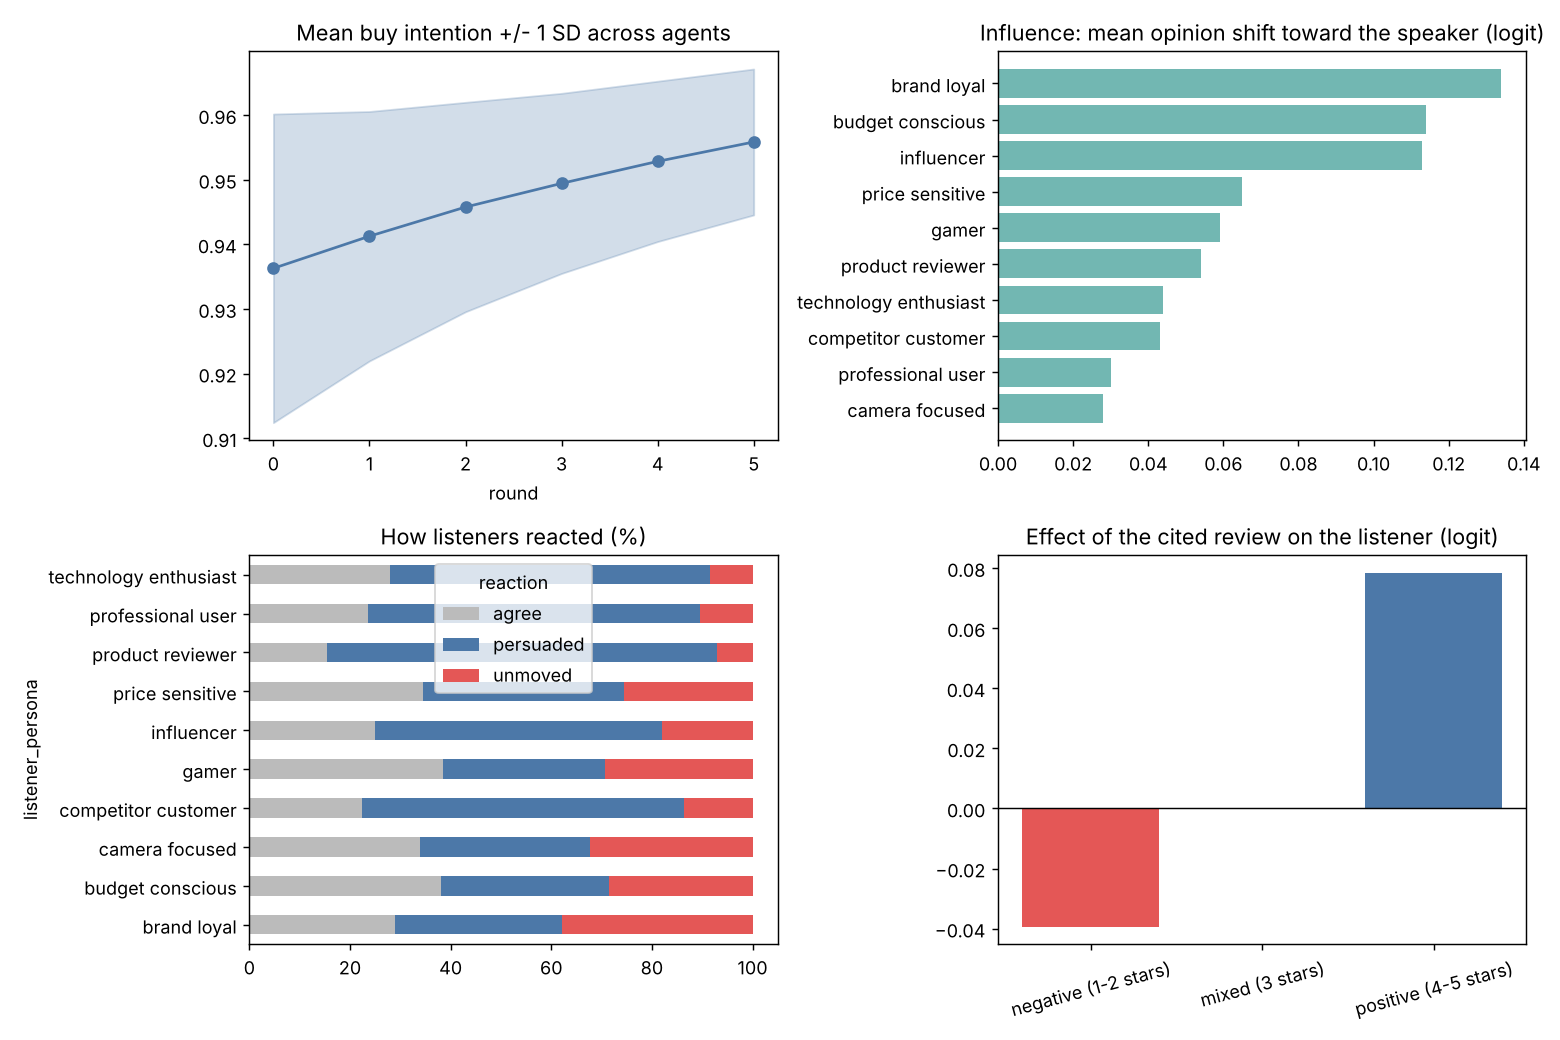

In [5]:
inf = L.groupby("speaker_persona").agg(messages=("round","size"), mean_shift_toward_speaker=("shift_toward","mean"),
        persuaded_pct=("reaction", lambda s: 100*(s=="persuaded").mean())).round(3).sort_values("mean_shift_toward_speaker", ascending=False)
display(inf)
display(Image("outputs/conversation_analysis.png"))

### How to read it
* **Influence** is the average opinion shift toward the speaker. Influencers carry more weight by design (credibility 1.0), and some personas are persuaded more easily than others, partly because of their susceptibility and partly because of which topics matter to them.
* **Topics:** price dominates by a wide margin (about two thirds of all exchanges) because it is the top concern of most agents; games, reading and camera follow. The conversations therefore mostly circulate price-related reviews.
* **Evidence effect (bottom right of the figure):** negative reviews pull listeners down and positive reviews push them up, which shows the cited evidence really drives the update.

## Why does mean intention drift upwards?

In [6]:
ev = L.dropna(subset=["evidence_stars"])
print(f"{(ev.evidence_stars >= 4).mean():.0%} of the reviews agents cited are 4-5 stars")
print(f"mean evidence term per exchange: {ev.evidence_term.mean():+.4f} logit   |   mean absolute social term: {ev.social_term.abs().mean():.4f}")
t = L.groupby("round").listener_after.agg(["mean","std"]).round(4); display(t)

97% of the reviews agents cited are 4-5 stars
mean evidence term per exchange: +0.0753 logit   |   mean absolute social term: 0.0705


,mean,std
round,,
1,0.9413,0.0193
2,0.9458,0.0162
3,0.9494,0.0140
4,0.9528,0.0124
5,0.9558,0.0113


Almost all cited reviews are positive, so the evidence term pushes opinions up. **Part of the upward drift is therefore the positive skew of the review data, not evidence that talking makes a product more appealing.** The spread across agents shrinks because paired agents move toward each other. Both effects are in the generated report so they cannot be over-interpreted.

## Integrity checks

In [7]:
recomputed = L.logit_before + L.weight*(L.speaker_logit - L.logit_before) + 0.5*L.weight*L.evidence_signal
display(pd.DataFrame([
    dict(check="messages that cite a retrieved real review", result=f"{L.evidence_review_id.notna().mean():.1%}"),
    dict(check="updates reproducible from the logged terms (max abs error)", result=f"{(recomputed - L.logit_after).abs().max():.2e}"),
]))

,check,result
0,messages that cite a retrieved real review,100.0%
1,updates reproducible from the logged terms (ma...,1.33e-15


These checks confirm the log is complete and every statement can be traced to a real review and a logged rule. They are about **explainability**, not about whether the agents behave like real consumers; that would need external data (Milestone 2).

## Where this appears in the deliverables
* **Report:** the generated section was appended to `outputs/report.md` (and saved as `outputs/conversation_report.md`).
* **Dashboard:** `python src/app.py --project-dir .` has an **Agent conversations** tab (filter by round and persona) and a **Reasoning analysis** tab with the same tables and figure.
* **Raw log:** `outputs/conversation_log.csv` has every exchange with all its reasoning terms.